In [118]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from flip7 import Deck,Draw,NumericDeck

In [2]:
d=Deck()
deck_counts=np.unique_counts(d)

In [8]:
len(d)

94

In [3]:
d

array(['0', '1', '2', '2', '3', '3', '3', '4', '4', '4', '4', '5', '5',
       '5', '5', '5', '6', '6', '6', '6', '6', '6', '7', '7', '7', '7',
       '7', '7', '7', '8', '8', '8', '8', '8', '8', '8', '8', '9', '9',
       '9', '9', '9', '9', '9', '9', '9', '10', '10', '10', '10', '10',
       '10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '11',
       '11', '11', '11', '11', '11', '12', '12', '12', '12', '12', '12',
       '12', '12', '12', '12', '12', '12', 'Freeze', 'Flip Three',
       'Second Chance', 'Freeze', 'Flip Three', 'Second Chance', 'Freeze',
       'Flip Three', 'Second Chance', 'x2', '+2', '+4', '+6', '+8', '+10'],
      dtype='<U21')

In [9]:
deck_counts

UniqueCountsResult(values=array(['+10', '+2', '+4', '+6', '+8', '0', '1', '10', '11', '12', '2',
       '3', '4', '5', '6', '7', '8', '9', 'Flip Three', 'Freeze',
       'Second Chance', 'x2'], dtype='<U21'), counts=array([ 1,  1,  1,  1,  1,  1,  1, 10, 11, 12,  2,  3,  4,  5,  6,  7,  8,
        9,  3,  3,  3,  1]))

In [4]:
numericdf=NumericDeck(d,True)

In [5]:
numericdf

UniqueCountsResult(values=array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12]), counts=array([ 1,  1,  3,  3,  5,  5,  7,  7,  9,  9, 11, 11, 12]))

In [6]:
expected_deck=np.round(np.sum((numericdf[0]*numericdf[1])/98),3)

In [7]:
expected_deck

np.float64(6.939)

In [17]:
prob_bust=dict()

In [126]:
d=Deck()
nd=NumericDeck(d)
prob_bust=dict()
for i in range(2,13):
    prob_bust[f"{nd[0][i]}"]=np.round((nd[1][i]-1)/(93),3)

In [121]:
prob_df=pd.DataFrame([list(prob_bust.keys()),list(prob_bust.values())]).transpose()

<BarContainer object of 11 artists>

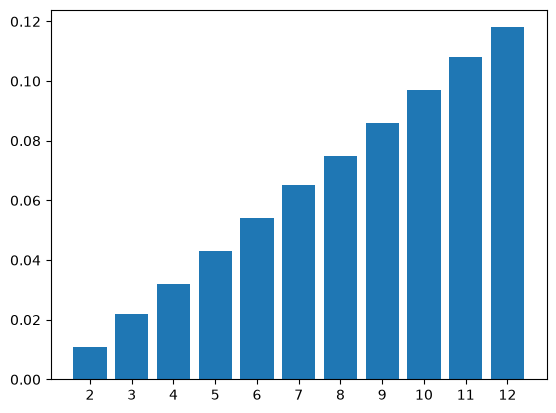

In [122]:
plt.bar(x=prob_df[0],height=prob_df[1])

In [127]:
prob_bust

{'2': np.float64(0.011),
 '3': np.float64(0.022),
 '4': np.float64(0.032),
 '5': np.float64(0.043),
 '6': np.float64(0.054),
 '7': np.float64(0.065),
 '8': np.float64(0.075),
 '9': np.float64(0.086),
 '10': np.float64(0.097),
 '11': np.float64(0.108),
 '12': np.float64(0.118)}

In [134]:
prob_bust2=dict()
for i in range(2,13):
    for j in range(2,13):
       if j==i:
           prob_bust2[f"{nd[0][i]} and {nd[0][j]}"]=0

       else:
            prob_bust2[f"{nd[0][i]} and {nd[0][j]}"]=np.round((nd[1][i]+nd[1][j]-2)/(91),3)

In [92]:
prob_bustdf2=pd.DataFrame([list(prob_bust2.keys()),list(prob_bust2.values())]).transpose()

In [97]:
prob_bustdf2.columns=['Cards','Probs']

In [132]:
# Make Function for easier reuse
dat=pd.DataFrame(columns=['Cards','Probs'])
for i in range(2,12):
    subdata=prob_bustdf2[12*(i-2):12*(i-1)-(i-1)]
    dat=pd.concat([subdata,dat])
dat=dat[dat['Probs']>0]
sorted_dat=dat.sort_values(by='Probs',ascending=False)

In [133]:
sorted_dat.head(55)

,Cards,Probs
109,11 and 12,0.231
98,10 and 12,0.22
87,9 and 12,0.209
97,10 and 11,0.209
86,9 and 11,0.198
76,8 and 12,0.198
85,9 and 10,0.187
75,8 and 11,0.187
65,7 and 12,0.187
64,7 and 11,0.176
